# 🔬 Eye Disease Classification — 95%+ · XAI (Grad-CAM + LIME) · Federated Learning

**Dataset:** Eye Disease Image Dataset — Augmented + Original  
**Architecture:** **MSCA-Net** — Multi-Scale Cross-Attention Network (**custom**)  
**Backbone:** EfficientNet-B3 (ImageNet pretrained, used as feature extractor)  
**Custom modules:** CBAM (Channel + Spatial) attention at 3 scales · 1×1 cross-scale projection · multi-scale fusion · custom 3-layer classifier head  
**Extras:** Grad-CAM · LIME · FedAvg · FedProx · Non-IID client splitting · Federated model export

---
### Notebook structure
| Cell | Content |
|------|---------|
| 1 | Install dependencies |
| 2 | Global config & imports |
| 3 | Data pipeline |
| 4 | Model definition |
| 5 | Training utilities (EMA, MixUp, CutMix, TTA) |
| 6 | **Training — Phase 1 (frozen) + Phase 2 (full fine-tune)** |
| 7 | Training history plot |
| 8 | **Evaluation — Classification report + Confusion matrix** |
| 9 | Save central model (checkpoint + TorchScript + metadata) |
| 10 | **XAI — Grad-CAM visualisation** |
| 11 | **XAI — LIME explanations** |
| 12 | **Federated Learning — Non-IID split + FedAvg + FedProx** |
| 13 | **Save & export federated global model** |
| 14 | Quick single-image inference test |


## 📦 Cell 1 — Install Dependencies

In [1]:
# Safe dependency setup
# Kaggle/Colab usually already include torch/torchvision.
# Reinstalling torch can break CUDA, so this cell installs only missing light packages.

import sys, subprocess, importlib.util

REQUIRED_IMPORTS = {
    "numpy": "numpy",
    "matplotlib": "matplotlib",
    "PIL": "Pillow",
    "cv2": "opencv-python-headless",
    "sklearn": "scikit-learn",
    "skimage": "scikit-image",
    "tqdm": "tqdm",
    "pandas": "pandas",
    "lime": "lime",
}

def install_if_missing(import_name, pip_name=None):
    if importlib.util.find_spec(import_name) is None:
        pkg = pip_name or import_name
        print(f"Installing missing package: {pkg}")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg])
    else:
        print(f"✅ {import_name} available")

# Hard check for torch/torchvision without reinstalling them.
for pkg in ["torch", "torchvision"]:
    if importlib.util.find_spec(pkg) is None:
        raise ImportError(
            f"{pkg} is not installed. On Kaggle, enable GPU runtime and use the default environment. "
            f"Do not pip-install torch unless absolutely necessary."
        )
    print(f"✅ {pkg} available")

for import_name, pip_name in REQUIRED_IMPORTS.items():
    install_if_missing(import_name, pip_name)

print("✅ Dependency check complete")


✅ torch available
✅ torchvision available
✅ numpy available
✅ matplotlib available
✅ PIL available
✅ cv2 available
✅ sklearn available
✅ skimage available
✅ tqdm available
✅ pandas available
✅ lime available
✅ Dependency check complete


## ⚙️ Cell 2 — Global Config & Imports

In [2]:
import os, sys, json, time, copy, random, warnings, math, platform
from pathlib import Path
from collections import defaultdict

# MPS fallback should be set before heavy torch ops.
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.cm as cm_plt
import seaborn as sns
import cv2
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import (
    DataLoader, Dataset, Subset, WeightedRandomSampler,
    ConcatDataset, random_split
)
from torchvision import datasets, transforms, models

from sklearn.metrics import (
    classification_report, confusion_matrix,
    accuracy_score, f1_score
)
from tqdm import tqdm

warnings.filterwarnings("ignore")

# ── Environment detection ───────────────────────────────────────────
IS_KAGGLE = Path("/kaggle/input").exists()
IS_MAC = (platform.system() == "Darwin")

# ── Reproducibility ────────────────────────────────────────────────
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True
    try:
        torch.set_float32_matmul_precision("high")
    except Exception:
        pass
else:
    torch.backends.cudnn.benchmark = False

# ── Device selection: Kaggle CUDA → Mac MPS → CPU ───────────────────
def select_device():
    if torch.cuda.is_available():
        return torch.device("cuda")
    if getattr(torch.backends, "mps", None) is not None and torch.backends.mps.is_available():
        return torch.device("mps")
    return torch.device("cpu")

DEVICE = select_device()
USE_CUDA = (DEVICE.type == "cuda")
USE_MPS = (DEVICE.type == "mps")

print(f"🖥️  Device : {DEVICE}   (kaggle={IS_KAGGLE}, mac={IS_MAC}, mps={USE_MPS}, cuda={USE_CUDA})")
if USE_CUDA:
    print(f"   GPU    : {torch.cuda.get_device_name(0)}")
    print(f"   Memory : {torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB")
elif USE_MPS:
    print("   Backend: Apple Metal Performance Shaders (MPS)")
    print("   Note   : PYTORCH_ENABLE_MPS_FALLBACK=1")
else:
    print("   Backend: CPU only — training will be slow")

# ── Dataset auto-detection: Kaggle + Mac + env var ──────────────────
def _is_eye_dataset_root(p: Path) -> bool:
    return (p / "Augmented Dataset").exists() and (p / "Original Dataset").exists()

def detect_eye_dataset_root():
    """
    Detects a folder containing:
        Augmented Dataset/
        Original Dataset/

    Priority:
        1. EYE_DATASET_DIR environment variable
        2. User-provided Kaggle path
        3. Common Kaggle dataset mount paths
        4. User's Mac path
        5. Recursive search under /kaggle/input
    """
    candidates = []

    env_path = os.environ.get("EYE_DATASET_DIR", "").strip()
    if env_path:
        candidates.append(Path(env_path))

    # User-provided Kaggle-style path
    candidates += [
        Path("/kaggle/input/datasets/shufanshahi/eye-disease-image-dataset/Eye Disease Image Dataset"),
        Path("/kaggle/input/eye-disease-image-dataset/Eye Disease Image Dataset"),
        Path("/kaggle/input/eye-disease-image-dataset"),
        Path("/kaggle/input/eye-disease-image-dataset/Eye MAC/Eye Disease Image Dataset"),

        # Local Mac path
        Path("/Users/shoumik/Downloads/Eye MAC/Eye Disease Image Dataset"),
    ]

    for p in candidates:
        if _is_eye_dataset_root(p):
            return p.resolve()

    # Kaggle fallback search — finds any parent with both required folders.
    if Path("/kaggle/input").exists():
        for aug_dir in Path("/kaggle/input").rglob("Augmented Dataset"):
            parent = aug_dir.parent
            if _is_eye_dataset_root(parent):
                return parent.resolve()

    raise FileNotFoundError(
        "❌ Could not auto-detect dataset root.\n\n"
        "Expected structure:\n"
        "  Eye Disease Image Dataset/\n"
        "    Augmented Dataset/\n"
        "    Original Dataset/\n\n"
        "Fix options:\n"
        "  1) On Kaggle, add the dataset to the notebook input.\n"
        "  2) Set environment variable EYE_DATASET_DIR to the parent folder.\n"
        "  3) Edit BASE_DIR manually in Cell 2.\n"
    )

BASE_DIR = detect_eye_dataset_root()
AUG_DIR = BASE_DIR / "Augmented Dataset"
ORG_DIR = BASE_DIR / "Original Dataset"

# ── Output paths: Kaggle writes to /kaggle/working ──────────────────
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path(".")
OUTPUT_DIR = WORK_DIR / "outputs"
MODEL_DIR = WORK_DIR / "models"
XAI_DIR = OUTPUT_DIR / "xai"
FED_DIR = MODEL_DIR / "federated"

for d in [OUTPUT_DIR, MODEL_DIR, XAI_DIR, FED_DIR]:
    d.mkdir(parents=True, exist_ok=True)

BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"
TS_MODEL_PATH = MODEL_DIR / "model_torchscript.pt"
FED_GLOBAL_PATH = FED_DIR / "federated_global.pth"
FED_TS_PATH = FED_DIR / "federated_global_torchscript.pt"

print("\n📂 Dataset root detected")
print(f"   BASE_DIR : {BASE_DIR}")
print(f"   AUG_DIR  : {AUG_DIR}")
print(f"   ORG_DIR  : {ORG_DIR}")
print(f"📦 Outputs will be saved to: {WORK_DIR.resolve()}")

# ── Hyperparameters ────────────────────────────────────────────────
_default_workers = 0 if (USE_MPS or IS_MAC) else min(4, max(2, (os.cpu_count() or 2) // 2))
_default_bs = 32 if USE_CUDA else (24 if USE_MPS else 16)

CFG = {
    "img_size"       : 224,
    "batch_size"     : _default_bs,

    # Phase 1 — frozen backbone, head/attention/projections only.
    # Lowered from 3e-3 to avoid early prediction collapse.
    "phase1_epochs"  : 8,
    "phase1_lr"      : 1e-3,

    # Phase 2 — full fine-tuning.
    "phase2_epochs"  : 35,
    "phase2_lr"      : 2e-4,

    "weight_decay"   : 1e-4,
    "dropout"        : 0.40,
    "val_split"      : 0.20,
    "num_workers"    : _default_workers,
    "patience"       : 12,
    "min_epochs_p2"  : 8,
    "target_acc"     : 95.0,

    # TTA: horizontal only. Vertical flip often hurts retinal/fundus validation.
    "eval_tta"       : True,
    "tta_flips"      : ("h",),

    "label_smooth"   : 0.05,
    "ema_decay"      : 0.999,
    "mixup_alpha"    : 0.20,
    "cutmix_alpha"   : 1.0,

    # Checkpoint safety
    "reset_best_checkpoint": True,
    "min_save_acc"         : 15.0,   # avoid saving random/collapsed early checkpoints

    # Federated Learning
    "fed_num_clients"   : 3,
    "fed_rounds"        : 10,
    "fed_local_epochs"  : 3,
    "fed_local_lr"      : 3e-4,
    "fed_proximal_mu"   : 0.01,
    "fed_non_iid_alpha" : 1.0,  # safer for rare classes than 0.7

    # XAI
    "xai_samples_per_class" : 2,
    "lime_num_samples"      : 1000,
    "lime_num_features"     : 10,
}

AMP_ENABLED = USE_CUDA

print("\n📋 Config loaded")
print(f"   Classes target : {CFG['target_acc']}%")
print(f"   Batch size     : {CFG['batch_size']}  |  workers : {CFG['num_workers']}")
print(f"   Phase1/Phase2  : {CFG['phase1_epochs']} + {CFG['phase2_epochs']} epochs")
print(f"   LR Phase1/2    : {CFG['phase1_lr']:.1e} / {CFG['phase2_lr']:.1e}")
print(f"   AMP mixed      : {AMP_ENABLED}")
print(f"   Fed clients    : {CFG['fed_num_clients']}")
print(f"   Fed rounds     : {CFG['fed_rounds']}  |  local epochs : {CFG['fed_local_epochs']}")
print(f"   Non-IID α      : {CFG['fed_non_iid_alpha']}")


🖥️  Device : cuda   (kaggle=True, mac=False, mps=False, cuda=True)
   GPU    : Tesla T4
   Memory : 15.6 GB

📂 Dataset root detected
   BASE_DIR : /kaggle/input/datasets/shufanshahi/eye-disease-image-dataset/Eye Disease Image Dataset
   AUG_DIR  : /kaggle/input/datasets/shufanshahi/eye-disease-image-dataset/Eye Disease Image Dataset/Augmented Dataset
   ORG_DIR  : /kaggle/input/datasets/shufanshahi/eye-disease-image-dataset/Eye Disease Image Dataset/Original Dataset
📦 Outputs will be saved to: /kaggle/working

📋 Config loaded
   Classes target : 95.0%
   Batch size     : 32  |  workers : 2
   Phase1/Phase2  : 8 + 35 epochs
   LR Phase1/2    : 1.0e-03 / 2.0e-04
   AMP mixed      : True
   Fed clients    : 3
   Fed rounds     : 10  |  local epochs : 3
   Non-IID α      : 1.0


## 📂 Cell 3 — Data Pipeline

In [3]:
# ══════════════════════════════════════════════════════════════════
#  CELL 3 — DATA PIPELINE
#  Auto paths are detected in Cell 2. This cell builds datasets/splits.
# ══════════════════════════════════════════════════════════════════

for p, name in [(AUG_DIR, "Augmented Dataset"), (ORG_DIR, "Original Dataset")]:
    if not p.exists():
        raise FileNotFoundError(f"❌ {name} not found at {p}")
    print(f"✅ Found: {p}")

IMG_SIZE = CFG["img_size"]

# Medical-image-safe augmentation:
# - no vertical flip by default
# - moderate rotation/color jitter
# - RandomErasing kept mild
TRAIN_TF = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.80, 1.0), ratio=(0.95, 1.05)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(12),
    transforms.ColorJitter(brightness=0.15, contrast=0.15, saturation=0.10, hue=0.03),
    transforms.RandomAffine(degrees=0, translate=(0.04, 0.04), scale=(0.96, 1.04), shear=3),
    transforms.RandomAutocontrast(p=0.10),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
    transforms.RandomErasing(p=0.08, scale=(0.02, 0.06)),
])

VAL_TF = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

aug_ds = datasets.ImageFolder(str(AUG_DIR), transform=TRAIN_TF)
org_tr_ds = datasets.ImageFolder(str(ORG_DIR), transform=TRAIN_TF)
org_val_ds = datasets.ImageFolder(str(ORG_DIR), transform=VAL_TF)

if aug_ds.classes != org_tr_ds.classes:
    raise ValueError(
        "❌ Class mismatch between Augmented Dataset and Original Dataset.\n"
        f"Aug classes: {aug_ds.classes}\n"
        f"Org classes: {org_tr_ds.classes}"
    )

CLASS_NAMES = aug_ds.classes
NUM_CLASSES = len(CLASS_NAMES)

print(f"\nClasses ({NUM_CLASSES}): {CLASS_NAMES}")

def stratified_split(targets, val_frac, seed=42):
    """
    Stratified split over Original Dataset only.
    Augmented Dataset is used only for training.
    """
    rng = np.random.default_rng(seed)
    by_class = defaultdict(list)

    for idx, lbl in enumerate(targets):
        by_class[int(lbl)].append(idx)

    tr, va = [], []

    for lbl, idxs in sorted(by_class.items()):
        idxs = np.array(idxs)
        rng.shuffle(idxs)

        n_val = max(1, int(round(len(idxs) * val_frac)))
        n_val = min(n_val, len(idxs) - 1) if len(idxs) > 1 else 1

        va.extend(idxs[:n_val].tolist())
        tr.extend(idxs[n_val:].tolist())

    rng.shuffle(tr)
    rng.shuffle(va)
    return tr, va

org_tr_idx, org_val_idx = stratified_split(org_tr_ds.targets, CFG["val_split"], seed=SEED)

org_tr_subset = Subset(org_tr_ds, org_tr_idx)
val_subset = Subset(org_val_ds, org_val_idx)

# Training = all augmented images + original-train subset
full_train_ds = ConcatDataset([aug_ds, org_tr_subset])
train_targets = list(aug_ds.targets) + [org_tr_ds.targets[i] for i in org_tr_idx]

train_size = len(full_train_ds)
val_size = len(val_subset)
class_counts = np.bincount(train_targets, minlength=NUM_CLASSES)
val_counts = np.bincount([org_val_ds.targets[i] for i in org_val_idx], minlength=NUM_CLASSES)

print(f"\nTrain: {train_size:,}  |  Val: {val_size:,}")

print("\nTraining class distribution BEFORE balancing:")
max_count = max(int(class_counts.max()), 1)
for i, (cls, cnt) in enumerate(zip(CLASS_NAMES, class_counts)):
    bar = "█" * int(cnt / max_count * 30)
    flag = "  ⚠ LOW" if cnt > 0 and cnt / max_count < 0.15 else ""
    print(f"  {i:2d}. {cls:<38} {int(cnt):>5}  {bar}{flag}")

nonzero = class_counts[class_counts > 0]
imb = class_counts.max() / max(nonzero.min(), 1)
print(f"\nImbalance ratio: {imb:.1f}×")

print("\nValidation class distribution:")
for i, (cls, cnt) in enumerate(zip(CLASS_NAMES, val_counts)):
    print(f"  {i:2d}. {cls:<38} {int(cnt):>5}")

# DataLoader settings
_nw = CFG["num_workers"]
_lk = dict(
    num_workers=_nw,
    pin_memory=USE_CUDA,
    persistent_workers=(_nw > 0),
)
if _nw > 0:
    _lk["prefetch_factor"] = 2

# Temporary unbalanced train_loader.
# Cell 3B replaces this with the balanced WeightedRandomSampler loader.
train_loader = DataLoader(
    full_train_ds,
    batch_size=CFG["batch_size"],
    shuffle=True,
    drop_last=True,
    **_lk
)

val_loader = DataLoader(
    val_subset,
    batch_size=CFG["batch_size"],
    shuffle=False,
    **_lk
)

print(f"\nTrain batches: {len(train_loader):,}  |  Val batches: {len(val_loader):,}")
print("✅ Data pipeline ready")
print("➡️  Run Cell 3B next to enable the balanced training sampler.")


✅ Found: /kaggle/input/datasets/shufanshahi/eye-disease-image-dataset/Eye Disease Image Dataset/Augmented Dataset
✅ Found: /kaggle/input/datasets/shufanshahi/eye-disease-image-dataset/Eye Disease Image Dataset/Original Dataset

Classes (10): ['Central Serous Chorioretinopathy', 'Diabetic Retinopathy', 'Disc Edema', 'Glaucoma', 'Healthy', 'Macular Scar', 'Myopia', 'Pterygium', 'Retinal Detachment', 'Retinitis Pigmentosa']

Train: 20,510  |  Val: 1,067

Training class distribution BEFORE balancing:
   0. Central Serous Chorioretinopathy         687  ████  ⚠ LOW
   1. Diabetic Retinopathy                    4651  ██████████████████████████████
   2. Disc Edema                               864  █████
   3. Glaucoma                                3959  █████████████████████████
   4. Healthy                                 3495  ██████████████████████
   5. Macular Scar                            2292  ██████████████
   6. Myopia                                  2651  █████████████████
   

## ⚖️ Cell 3B — Separate Dataset Balancing

This cell keeps the dataset files unchanged, but rebuilds `train_loader` with `WeightedRandomSampler` and prints before/after sampling balance.


In [4]:
# ══════════════════════════════════════════════════════════════════
#  CELL 3B — SEPARATE DATASET BALANCING + BALANCE REPORT
# ══════════════════════════════════════════════════════════════════

from torch.utils.data import WeightedRandomSampler

def print_class_distribution(title, counts, class_names):
    """
    Pretty class distribution printer.
    Shows total samples, imbalance ratio, class counts, percentage, and bar.
    """
    counts = np.array(counts).astype(int)
    total = int(counts.sum())

    max_count = int(counts.max()) if counts.size > 0 else 1
    nonzero_counts = counts[counts > 0]
    min_nonzero = int(nonzero_counts.min()) if len(nonzero_counts) > 0 else 1

    imbalance_ratio = max_count / max(min_nonzero, 1)

    print(f"\n{title}")
    print("=" * 95)
    print(f"Total samples    : {total:,}")
    print(f"Imbalance ratio  : {imbalance_ratio:.1f}×")
    print("-" * 95)

    for i, cls in enumerate(class_names):
        cnt = int(counts[i]) if i < len(counts) else 0
        pct = (cnt / total * 100) if total > 0 else 0.0
        bar_len = int((cnt / max_count) * 30) if max_count > 0 else 0
        bar = "█" * bar_len
        flag = "  ⚠ LOW" if cnt > 0 and cnt / max_count < 0.15 else ""
        print(f"{i:2d}. {cls:<42} {cnt:>6}  {pct:>6.2f}%  {bar}{flag}")


def make_balanced_sampler_from_targets(targets, num_classes, num_samples=None):
    """
    WeightedRandomSampler for imbalanced classification.

    sample_weight = 1 / class_count[label]

    This does not edit files and does not permanently duplicate images.
    It changes only how samples are drawn in each training epoch.
    """
    targets = np.array(targets).astype(int)

    class_counts_local = np.bincount(targets, minlength=num_classes)
    if np.any(class_counts_local == 0):
        missing = np.where(class_counts_local == 0)[0].tolist()
        raise ValueError(f"❌ Missing classes in training targets: {missing}")

    sample_weights = np.array(
        [1.0 / class_counts_local[label] for label in targets],
        dtype=np.float32
    )

    if num_samples is None:
        num_samples = len(targets)

    sampler_local = WeightedRandomSampler(
        weights=torch.from_numpy(sample_weights),
        num_samples=int(num_samples),
        replacement=True
    )

    return sampler_local, class_counts_local, sample_weights


def preview_sampler_distribution(targets, sampler_local, num_classes):
    """
    Simulates one sampled epoch and returns the sampled class counts.
    This does not load images, so it is fast.
    """
    targets = np.array(targets).astype(int)
    sampled_indices = list(iter(sampler_local))
    sampled_labels = targets[sampled_indices]
    sampled_counts = np.bincount(sampled_labels, minlength=num_classes)
    return sampled_counts


# 1. Original distribution
print_class_distribution(
    title="Original training distribution BEFORE balancing",
    counts=class_counts,
    class_names=CLASS_NAMES
)

# 2. Create balanced sampler
balanced_train_sampler, original_train_counts, train_sample_weights = make_balanced_sampler_from_targets(
    targets=train_targets,
    num_classes=NUM_CLASSES,
    num_samples=train_size
)

# 3. Preview one sampled epoch
balanced_preview_counts = preview_sampler_distribution(
    targets=train_targets,
    sampler_local=balanced_train_sampler,
    num_classes=NUM_CLASSES
)

print_class_distribution(
    title="Sampled training distribution AFTER WeightedRandomSampler preview",
    counts=balanced_preview_counts,
    class_names=CLASS_NAMES
)

expected_per_class = train_size / NUM_CLASSES
print(f"\nExpected balanced samples per class per epoch ≈ {expected_per_class:.0f}")
print("Small random variation is normal because WeightedRandomSampler samples with replacement.")

# 4. Rebuild central training loader using balanced sampler
train_loader = DataLoader(
    full_train_ds,
    batch_size=CFG["batch_size"],
    sampler=balanced_train_sampler,
    shuffle=False,
    drop_last=True,
    **_lk
)

print("\n✅ Balanced central train_loader ready")
print(f"Train batches     : {len(train_loader):,}")
print(f"Batch size        : {CFG['batch_size']}")
print("Balancing method  : WeightedRandomSampler")
print("Replacement       : True")
print("Dataset changed   : No, only sampling strategy changed")



Original training distribution BEFORE balancing
Total samples    : 20,510
Imbalance ratio  : 40.1×
-----------------------------------------------------------------------------------------------
 0. Central Serous Chorioretinopathy              687    3.35%  ████  ⚠ LOW
 1. Diabetic Retinopathy                         4651   22.68%  ██████████████████████████████
 2. Disc Edema                                    864    4.21%  █████
 3. Glaucoma                                     3959   19.30%  █████████████████████████
 4. Healthy                                      3495   17.04%  ██████████████████████
 5. Macular Scar                                 2292   11.18%  ██████████████
 6. Myopia                                       2651   12.93%  █████████████████
 7. Pterygium                                     116    0.57%    ⚠ LOW
 8. Retinal Detachment                            850    4.14%  █████
 9. Retinitis Pigmentosa                          945    4.61%  ██████

Sampled tra

## 🧠 Cell 4 — Model (EfficientNet-B3)

In [5]:
# ══════════════════════════════════════════════════════════════════
#  MSCA-Net  —  Multi-Scale Cross-Attention Network  (CUSTOM)
# ══════════════════════════════════════════════════════════════════
#
#  A custom hybrid architecture for retinal disease classification.
#  Combines a pretrained CNN feature extractor with three novel
#  components designed by us:
#
#    (1)  Multi-scale feature extraction   — backbone split into 3
#         pathways capturing low / mid / high level retinal features.
#    (2)  CBAM attention at every scale    — Channel-wise SE attention
#         + spatial 7×7 attention, applied independently at each scale.
#    (3)  Cross-scale fusion + custom head — 1×1 projections to a
#         shared embedding, concatenated, fed to a 3-layer classifier
#         with progressive dropout decay (40% → 30% → 20%).
#
#  Backbone : EfficientNet-B3 (ImageNet pretrained, used as feature
#             extractor only; we add ~1.5 M trainable custom params on
#             top).
# ══════════════════════════════════════════════════════════════════


class ChannelAttention(nn.Module):
    """Channel attention via shared MLP over avg- and max-pooled features."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.mlp = nn.Sequential(
            nn.Linear(channels, hidden, bias=False),
            nn.SiLU(inplace=True),
            nn.Linear(hidden, channels, bias=False),
        )

    def forward(self, x):
        b, c, _, _ = x.shape
        avg_p = F.adaptive_avg_pool2d(x, 1).view(b, c)
        max_p = F.adaptive_max_pool2d(x, 1).view(b, c)
        attn  = torch.sigmoid(self.mlp(avg_p) + self.mlp(max_p))
        return x * attn.view(b, c, 1, 1)


class SpatialAttention(nn.Module):
    """Spatial attention from concatenated avg/max maps along channel dim."""
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size,
                              padding=kernel_size // 2, bias=False)

    def forward(self, x):
        avg_c = x.mean(dim=1, keepdim=True)
        max_c, _ = x.max(dim=1, keepdim=True)
        attn = torch.sigmoid(self.conv(torch.cat([avg_c, max_c], dim=1)))
        return x * attn


class CBAMBlock(nn.Module):
    """Combined Channel-then-Spatial attention (CBAM)."""
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(channels, reduction)
        self.sa = SpatialAttention()

    def forward(self, x):
        return self.sa(self.ca(x))


class MSCANet(nn.Module):
    """
    Multi-Scale Cross-Attention Network — the custom model.

    Forward flow:
        x → stem
          → stage1 (low-level)  → CBAM → 1×1 proj
          → stage2 (mid-level)  → CBAM → 1×1 proj
          → stage3 (high-level) → CBAM → 1×1 proj
          → GAP each, concat, custom 3-layer classifier
    """

    def __init__(self, num_classes, dropout=0.40,
                 freeze_backbone=True, proj_dim=256):
        super().__init__()
        backbone = models.efficientnet_b3(
            weights=models.EfficientNet_B3_Weights.IMAGENET1K_V1)
        feats = backbone.features

        # Split EfficientNet-B3 into three multi-scale pathways
        self.stem   = feats[0]
        self.stage1 = nn.Sequential(*[feats[i] for i in range(1, 3)])  # low
        self.stage2 = nn.Sequential(*[feats[i] for i in range(3, 6)])  # mid
        self.stage3 = nn.Sequential(*[feats[i] for i in range(6, 9)])  # high

        # Detect channel counts robustly across torchvision versions
        with torch.no_grad():
            dummy = torch.zeros(1, 3, 224, 224)
            x  = self.stem(dummy)
            f1 = self.stage1(x);  c1 = f1.shape[1]
            f2 = self.stage2(f1); c2 = f2.shape[1]
            f3 = self.stage3(f2); c3 = f3.shape[1]
        self._scale_channels = (c1, c2, c3)

        # Custom CBAM attention at each scale
        self.att1 = CBAMBlock(c1)
        self.att2 = CBAMBlock(c2)
        self.att3 = CBAMBlock(c3)

        # 1×1 projections to a shared cross-scale embedding
        self.proj1 = nn.Conv2d(c1, proj_dim, kernel_size=1, bias=False)
        self.proj2 = nn.Conv2d(c2, proj_dim, kernel_size=1, bias=False)
        self.proj3 = nn.Conv2d(c3, proj_dim, kernel_size=1, bias=False)

        # Custom 3-layer classifier head with progressive dropout decay
        fused_dim = proj_dim * 3
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(fused_dim, 512),
            nn.BatchNorm1d(512),
            nn.SiLU(inplace=True),
            nn.Dropout(dropout * 0.75),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.SiLU(inplace=True),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, num_classes),
        )

        if freeze_backbone:
            self._freeze_backbone()

    # ── Helpers ─────────────────────────────────────────────────────
    def _freeze_backbone(self):
        for m in (self.stem, self.stage1, self.stage2, self.stage3):
            for p in m.parameters():
                p.requires_grad = False

    def unfreeze_backbone(self):
        for p in self.parameters():
            p.requires_grad = True

    # ── Forward ─────────────────────────────────────────────────────
    def forward(self, x):
        x  = self.stem(x)
        f1 = self.stage1(x)        # low-level
        f2 = self.stage2(f1)       # mid-level
        f3 = self.stage3(f2)       # high-level

        # CBAM attention per scale
        f1 = self.att1(f1)
        f2 = self.att2(f2)
        f3 = self.att3(f3)

        # Project to common dim, global-pool, fuse
        f1 = F.adaptive_avg_pool2d(self.proj1(f1), 1).flatten(1)
        f2 = F.adaptive_avg_pool2d(self.proj2(f2), 1).flatten(1)
        f3 = F.adaptive_avg_pool2d(self.proj3(f3), 1).flatten(1)

        fused = torch.cat([f1, f2, f3], dim=1)
        return self.classifier(fused)


# Public name kept the same so the rest of the notebook works unchanged
MODEL_NAME = 'MSCA-Net (Multi-Scale Cross-Attention Network — custom)'


def build_model(num_classes, dropout=0.40, freeze_backbone=True):
    return MSCANet(num_classes=num_classes,
                   dropout=dropout,
                   freeze_backbone=freeze_backbone).to(DEVICE)


model = build_model(NUM_CLASSES, dropout=CFG['dropout'], freeze_backbone=True)
total     = sum(p.numel() for p in model.parameters())
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
c1, c2, c3 = model._scale_channels
print(f'🧠 {MODEL_NAME}')
print(f'   Scale channels  : low={c1}  mid={c2}  high={c3}')
print(f'   Total params    : {total:>12,}')
print(f'   Trainable (Ph1) : {trainable:>12,}  '
      f'({100*trainable/total:.1f}% — only attention + projections + head)')

with torch.no_grad():
    dummy = torch.randn(2, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
    print(f'   Forward pass    : {list(dummy.shape)} → {list(model(dummy).shape)}')


Downloading: "https://download.pytorch.org/models/efficientnet_b3_rwightman-b3899882.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b3_rwightman-b3899882.pth


100%|██████████| 47.2M/47.2M [00:00<00:00, 209MB/s]


🧠 MSCA-Net (Multi-Scale Cross-Attention Network — custom)
   Scale channels  : low=32  mid=136  high=1536
   Total params    :   11,959,512
   Trainable (Ph1) :    1,263,280  (10.6% — only attention + projections + head)
   Forward pass    : [2, 3, 224, 224] → [2, 10]


## 🧩 Cell 4B — Model Architecture Diagram (code-generated)

This cell generates a **VGG-style architecture diagram** for the custom **MSCA-Net** and saves it to `outputs/msca_architecture.png`.

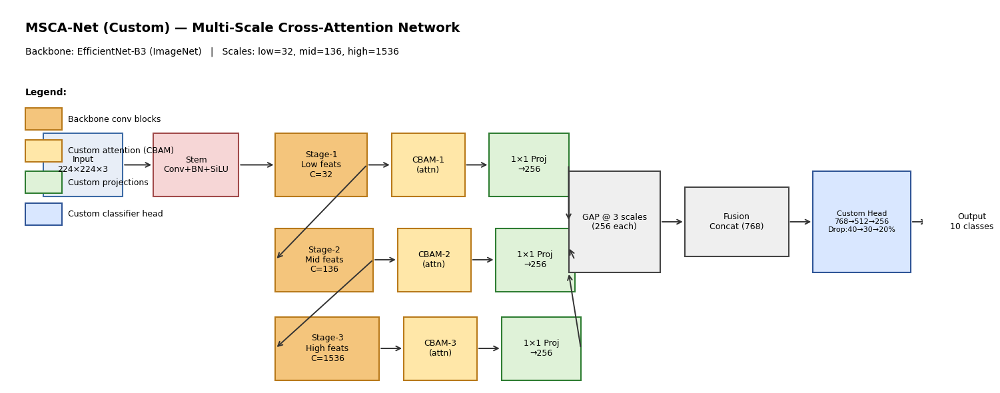

✅ Saved architecture diagram → /kaggle/working/outputs/msca_architecture.png


In [6]:
from matplotlib.patches import Rectangle, FancyArrowPatch

def _box(ax, xy, w, h, label, fc='#F4C57C', ec='#B8791A', lw=1.5, fontsize=9):
    x, y = xy
    r = Rectangle((x, y), w, h, facecolor=fc, edgecolor=ec, linewidth=lw)
    ax.add_patch(r)
    ax.text(x + w/2, y + h/2, label, ha='center', va='center', fontsize=fontsize)
    return r


def _arrow(ax, x0, y0, x1, y1, color='#333333'):
    a = FancyArrowPatch((x0, y0), (x1, y1), arrowstyle='->', mutation_scale=12,
                        linewidth=1.4, color=color)
    ax.add_patch(a)


def plot_msca_architecture(model, save_path=OUTPUT_DIR/'msca_architecture.png'):
    """Create and save a clean MSCA-Net architecture diagram."""
    if not hasattr(model, '_scale_channels'):
        raise RuntimeError('Expected MSCA-Net model with `_scale_channels`.')

    c1, c2, c3 = model._scale_channels

    fig, ax = plt.subplots(figsize=(15, 6))
    ax.set_xlim(0, 15)
    ax.set_ylim(0, 6)
    ax.axis('off')

    ax.text(0.3, 5.6, 'MSCA-Net (Custom) — Multi-Scale Cross-Attention Network',
            fontsize=14, fontweight='bold')
    ax.text(0.3, 5.25, f'Backbone: EfficientNet-B3 (ImageNet)   |   Scales: low={c1}, mid={c2}, high={c3}',
            fontsize=10)

    # Layout coordinates
    y = 3.0
    h = 1.0
    x = 0.6

    # Input
    b_in = _box(ax, (x, y), 1.3, h, 'Input\n224×224×3', fc='#E8EEF7', ec='#3C6AA5')
    x += 1.8

    # Stem
    b_stem = _box(ax, (x, y), 1.4, h, 'Stem\nConv+BN+SiLU', fc='#F6D6D6', ec='#A14A4A')
    _arrow(ax, b_in.get_x()+b_in.get_width(), y+h/2, b_stem.get_x(), y+h/2)
    x += 2.0

    # Stage 1
    b_s1  = _box(ax, (x, y), 1.5, h, f'Stage-1\nLow feats\nC={c1}', fc='#F4C57C', ec='#B8791A')
    _arrow(ax, b_stem.get_x()+b_stem.get_width(), y+h/2, b_s1.get_x(), y+h/2)
    x += 1.9
    b_a1  = _box(ax, (x, y), 1.2, h, 'CBAM-1\n(attn)', fc='#FFE7A8', ec='#B8791A')
    _arrow(ax, b_s1.get_x()+b_s1.get_width(), y+h/2, b_a1.get_x(), y+h/2)
    x += 1.6
    b_p1  = _box(ax, (x, y), 1.3, h, '1×1 Proj\n→256', fc='#DFF2D8', ec='#2E7D32')
    _arrow(ax, b_a1.get_x()+b_a1.get_width(), y+h/2, b_p1.get_x(), y+h/2)

    # Stage 2 (branch continues from Stage1 features)
    x2 = 4.4
    y2 = 1.5
    b_s2  = _box(ax, (x2, y2), 1.6, h, f'Stage-2\nMid feats\nC={c2}', fc='#F4C57C', ec='#B8791A')
    _arrow(ax, b_s1.get_x()+b_s1.get_width(), y+h/2, b_s2.get_x(), y2+h/2)
    x2 += 2.0
    b_a2  = _box(ax, (x2, y2), 1.2, h, 'CBAM-2\n(attn)', fc='#FFE7A8', ec='#B8791A')
    _arrow(ax, b_s2.get_x()+b_s2.get_width(), y2+h/2, b_a2.get_x(), y2+h/2)
    x2 += 1.6
    b_p2  = _box(ax, (x2, y2), 1.3, h, '1×1 Proj\n→256', fc='#DFF2D8', ec='#2E7D32')
    _arrow(ax, b_a2.get_x()+b_a2.get_width(), y2+h/2, b_p2.get_x(), y2+h/2)

    # Stage 3
    x3 = 4.4
    y3 = 0.1
    b_s3  = _box(ax, (x3, y3), 1.7, h, f'Stage-3\nHigh feats\nC={c3}', fc='#F4C57C', ec='#B8791A')
    _arrow(ax, b_s2.get_x()+b_s2.get_width(), y2+h/2, b_s3.get_x(), y3+h/2)
    x3 += 2.1
    b_a3  = _box(ax, (x3, y3), 1.2, h, 'CBAM-3\n(attn)', fc='#FFE7A8', ec='#B8791A')
    _arrow(ax, b_s3.get_x()+b_s3.get_width(), y3+h/2, b_a3.get_x(), y3+h/2)
    x3 += 1.6
    b_p3  = _box(ax, (x3, y3), 1.3, h, '1×1 Proj\n→256', fc='#DFF2D8', ec='#2E7D32')
    _arrow(ax, b_a3.get_x()+b_a3.get_width(), y3+h/2, b_p3.get_x(), y3+h/2)

    # Global pooling + fusion
    x_f = 9.2
    b_gap = _box(ax, (x_f, 1.8), 1.5, 1.6, 'GAP @ 3 scales\n(256 each)', fc='#EFEFEF', ec='#444444')
    _arrow(ax, b_p1.get_x()+b_p1.get_width(), y+h/2, b_gap.get_x(), 2.6)
    _arrow(ax, b_p2.get_x()+b_p2.get_width(), y2+h/2, b_gap.get_x(), 2.2)
    _arrow(ax, b_p3.get_x()+b_p3.get_width(), y3+h/2, b_gap.get_x(), 1.8)

    x_c = 11.1
    b_fuse = _box(ax, (x_c, 2.05), 1.7, 1.1, 'Fusion\nConcat (768)', fc='#EFEFEF', ec='#444444')
    _arrow(ax, b_gap.get_x()+b_gap.get_width(), 2.6, b_fuse.get_x(), 2.6)

    # Classifier
    x_h = 13.2
    b_head = _box(ax, (x_h, 1.8), 1.6, 1.6,
                  'Custom Head\n768→512→256\nDrop:40→30→20%',
                  fc='#D9E7FF', ec='#2F5597', fontsize=8)
    _arrow(ax, b_fuse.get_x()+b_fuse.get_width(), 2.6, b_head.get_x(), 2.6)

    # Output
    b_out = _box(ax, (x_h+1.9, 2.15), 1.4, 0.9, f'Output\n{NUM_CLASSES} classes',
                 fc='#E2F0D9', ec='#2E7D32')
    _arrow(ax, b_head.get_x()+b_head.get_width(), 2.6, b_out.get_x(), 2.6)

    # Legend
    ax.text(0.3, 4.6, 'Legend:', fontsize=10, fontweight='bold')
    _box(ax, (0.3, 4.05), 0.6, 0.35, '', fc='#F4C57C', ec='#B8791A')
    ax.text(1.0, 4.22, 'Backbone conv blocks', fontsize=9, va='center')
    _box(ax, (0.3, 3.55), 0.6, 0.35, '', fc='#FFE7A8', ec='#B8791A')
    ax.text(1.0, 3.72, 'Custom attention (CBAM)', fontsize=9, va='center')
    _box(ax, (0.3, 3.05), 0.6, 0.35, '', fc='#DFF2D8', ec='#2E7D32')
    ax.text(1.0, 3.22, 'Custom projections', fontsize=9, va='center')
    _box(ax, (0.3, 2.55), 0.6, 0.35, '', fc='#D9E7FF', ec='#2F5597')
    ax.text(1.0, 2.72, 'Custom classifier head', fontsize=9, va='center')

    plt.tight_layout()
    save_path = Path(save_path)
    save_path.parent.mkdir(exist_ok=True, parents=True)
    plt.savefig(save_path, dpi=200, bbox_inches='tight')
    plt.show()
    print(f'✅ Saved architecture diagram → {save_path}')


plot_msca_architecture(model)

## 🔧 Cell 5 — Training Utilities

In [7]:
class ModelEMA:
    def __init__(self, model, decay=0.997):
        self.ema = copy.deepcopy(model).eval()
        self.decay = decay; self.updates = 0
        for p in self.ema.parameters(): p.requires_grad_(False)

    @torch.no_grad()
    def update(self, model):
        self.updates += 1
        d = min(self.decay, (1+self.updates)/(10+self.updates))
        for (_, v), (_, mv) in zip(model.state_dict().items(), self.ema.state_dict().items()):
            if mv.dtype.is_floating_point: mv.mul_(d).add_(v.detach(), alpha=1-d)
            else: mv.copy_(v)


def one_hot(lbls, nc, smooth=0.0):
    y = torch.zeros(lbls.size(0), nc, device=lbls.device)
    y.scatter_(1, lbls.unsqueeze(1), 1.0)
    return y*(1-smooth) + smooth/nc if smooth > 0 else y

def mixup(imgs, lbls, nc, alpha=0.20):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(imgs.size(0), device=imgs.device)
    return lam*imgs+(1-lam)*imgs[idx], lam*one_hot(lbls,nc,0.02)+(1-lam)*one_hot(lbls[idx],nc,0.02)

def rand_bbox(sz, lam):
    _,_,H,W = sz; r=np.sqrt(1-lam)
    cw,ch = int(W*r),int(H*r)
    cx,cy = np.random.randint(W),np.random.randint(H)
    return (np.clip(cx-cw//2,0,W),np.clip(cy-ch//2,0,H),
            np.clip(cx+cw//2,0,W),np.clip(cy+ch//2,0,H))

def cutmix(imgs, lbls, nc, alpha=1.0):
    lam = np.random.beta(alpha, alpha)
    idx = torch.randperm(imgs.size(0), device=imgs.device)
    x1,y1,x2,y2 = rand_bbox(imgs.size(), lam)
    mixed = imgs.clone(); mixed[:,:,y1:y2,x1:x2] = imgs[idx,:,y1:y2,x1:x2]
    lam_adj = 1-(x2-x1)*(y2-y1)/(imgs.size(-1)*imgs.size(-2))
    return mixed, lam_adj*one_hot(lbls,nc,0.02)+(1-lam_adj)*one_hot(lbls[idx],nc,0.02)

def soft_ce(logits, targets, smooth=0.05):
    if targets.ndim == 1: return F.cross_entropy(logits, targets, label_smoothing=smooth)
    return -(targets * F.log_softmax(logits, dim=1)).sum(dim=1).mean()

@torch.no_grad()
def tta_forward(model, imgs, flips=('h','v')):
    logits = model(imgs); n = 1
    if 'h' in flips:  logits += model(torch.flip(imgs,[3])); n+=1
    if 'v' in flips:  logits += model(torch.flip(imgs,[2])); n+=1
    if 'hv' in flips: logits += model(torch.flip(imgs,[2,3])); n+=1
    return logits/n

def save_ckpt(model, optimizer, epoch, val_acc, tta_acc, score, path, extra=None):
    d = dict(epoch=epoch, val_acc=val_acc, val_acc_tta=tta_acc, score=score,
             model_state=model.state_dict(), optimizer_state=optimizer.state_dict(),
             class_names=CLASS_NAMES, cfg=CFG)
    if extra: d.update(extra)
    torch.save(d, path)

def load_ckpt(model, path, optimizer=None, strict=True):
    if not Path(path).exists():
        raise FileNotFoundError(
            f'❌ Checkpoint missing: {path}\n'
            'Run Cell 6 (training) first.')
    # PyTorch 2.6+ defaults weights_only=True; our checkpoints contain dicts/lists.
    try:
        ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:  # older PyTorch without weights_only kwarg
        ckpt = torch.load(path, map_location=DEVICE)
    model.load_state_dict(ckpt['model_state'], strict=strict)
    if optimizer and 'optimizer_state' in ckpt:
        optimizer.load_state_dict(ckpt['optimizer_state'])
    print(f'✅ Loaded: {Path(path).name}  |  epoch={ckpt.get("epoch","?")}  '
          f'val={ckpt.get("val_acc",0):.2f}%')
    return ckpt

print('✅ Training utilities ready')


✅ Training utilities ready


## 🏋️ Cell 6 — Training (Phase 1 → Phase 2)

In [8]:
TARGET_ACC = CFG["target_acc"]
# AMP_ENABLED was set in Cell 2. CUDA uses mixed precision; MPS/CPU use float32.

import contextlib

def _autocast_ctx():
    """Autocast only on CUDA."""
    if AMP_ENABLED:
        return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=True)
    return contextlib.nullcontext()


def _set_backbone_eval_if_phase1(model, phase):
    """
    Important bug fix:
    During Phase 1, backbone parameters are frozen, but BatchNorm running stats
    would still update if the whole model stays in train mode.
    This keeps frozen EfficientNet blocks in eval mode and prevents BN-stat drift.
    """
    if phase == 1:
        for name in ["stem", "stage1", "stage2", "stage3"]:
            if hasattr(model, name):
                getattr(model, name).eval()


def train_epoch(model, loader, optimizer, scheduler, scaler, ema, epoch, phase):
    model.train()
    _set_backbone_eval_if_phase1(model, phase)

    tot_loss = 0.0
    correct = 0
    total = 0

    # Keep heavy mixed augmentation out of Phase 1.
    use_aug = (phase == 2) and (epoch >= 3)

    bar = tqdm(loader, desc=f"  Ph{phase} Ep{epoch:>3}", leave=False, ncols=96)

    for imgs, lbls in bar:
        imgs = imgs.to(DEVICE, non_blocking=True)
        lbls = lbls.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        targets = lbls
        if use_aug:
            r = random.random()
            if r < 0.25:
                imgs, targets = cutmix(imgs, lbls, NUM_CLASSES, CFG["cutmix_alpha"])
            elif r < 0.45:
                imgs, targets = mixup(imgs, lbls, NUM_CLASSES, CFG["mixup_alpha"])

        with _autocast_ctx():
            logits = model(imgs)
            loss = soft_ce(logits, targets, smooth=CFG["label_smooth"])

        if not torch.isfinite(loss):
            optimizer.zero_grad(set_to_none=True)
            bar.set_postfix(loss="NaN-skip")
            continue

        if AMP_ENABLED:
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()

        if scheduler is not None:
            scheduler.step()

        if ema is not None:
            ema.update(model)

        with torch.no_grad():
            preds = logits.argmax(1)
            ref = lbls if targets.ndim == 1 else targets.argmax(1)
            correct += (preds == ref).sum().item()
            total += lbls.size(0)
            tot_loss += loss.item() * lbls.size(0)

        bar.set_postfix(loss=f"{loss.item():.3f}", lr=f"{optimizer.param_groups[-1]['lr']:.1e}")

    return tot_loss / max(total, 1), 100.0 * correct / max(total, 1)


@torch.no_grad()
def validate(model, loader, use_tta=False, return_preds=False):
    model.eval()

    tot_loss = 0.0
    correct = 0
    total = 0
    flips = CFG["tta_flips"] if use_tta else ()

    all_preds = []

    for imgs, lbls in loader:
        imgs = imgs.to(DEVICE, non_blocking=True)
        lbls = lbls.to(DEVICE, non_blocking=True)

        logits = tta_forward(model, imgs, flips) if use_tta else model(imgs)

        loss = F.cross_entropy(logits, lbls)
        tot_loss += loss.item() * lbls.size(0)

        preds = logits.argmax(1)
        correct += (preds == lbls).sum().item()
        total += lbls.size(0)

        if return_preds:
            all_preds.append(preds.detach().cpu().numpy())

    avg_loss = tot_loss / max(total, 1)
    acc = 100.0 * correct / max(total, 1)

    if return_preds:
        if len(all_preds) == 0:
            return avg_loss, acc, np.array([], dtype=int)
        return avg_loss, acc, np.concatenate(all_preds)

    return avg_loss, acc


def _verify_checkpoint(path, expected_acc, use_tta=False, tol=1.0):
    """
    Reload checkpoint into a fresh model and verify the same metric type used for saving.
    This fixes misleading logs such as saving by TTA score but verifying by non-TTA score.
    """
    fresh = build_model(NUM_CLASSES, dropout=CFG["dropout"], freeze_backbone=False)

    try:
        ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    except TypeError:
        ckpt = torch.load(path, map_location=DEVICE)

    fresh.load_state_dict(ckpt["model_state"], strict=True)
    fresh.eval()

    _, measured = validate(fresh, val_loader, use_tta=use_tta)

    del fresh
    if USE_CUDA:
        torch.cuda.empty_cache()

    ok = abs(measured - expected_acc) <= tol
    return ok, measured


def _candidate_list(model, ema, va, va_tta, ema_va, ema_tta, live_unique, ema_unique):
    """
    Build checkpoint candidates.
    Uses raw validation if raw beats TTA, and TTA only if it actually helps.
    """
    min_unique = max(3, min(NUM_CLASSES, NUM_CLASSES // 2))
    live_ok = live_unique >= min_unique
    ema_ok = ema_unique >= min_unique

    candidates = []

    if live_ok:
        candidates.append({
            "name": "live",
            "model": model,
            "score": va,
            "verify_tta": False,
            "val_acc": va,
            "val_acc_tta": va_tta,
            "unique": live_unique,
        })

        if CFG["eval_tta"] and va_tta > va:
            candidates.append({
                "name": "live_tta",
                "model": model,
                "score": va_tta,
                "verify_tta": True,
                "val_acc": va,
                "val_acc_tta": va_tta,
                "unique": live_unique,
            })

    if ema_ok:
        candidates.append({
            "name": "EMA",
            "model": ema.ema,
            "score": ema_va,
            "verify_tta": False,
            "val_acc": ema_va,
            "val_acc_tta": ema_tta,
            "unique": ema_unique,
        })

        if CFG["eval_tta"] and ema_tta > ema_va:
            candidates.append({
                "name": "EMA_tta",
                "model": ema.ema,
                "score": ema_tta,
                "verify_tta": True,
                "val_acc": ema_va,
                "val_acc_tta": ema_tta,
                "unique": ema_unique,
            })

    return candidates, live_ok, ema_ok


def run_phase(phase, model, ema, max_epochs, lr, patience_limit, min_epochs=0):
    print(f"\n{'=' * 70}")
    print(f"  PHASE {phase}  |  epochs={max_epochs}  lr={lr:.1e}  patience={patience_limit}")
    print(f"{'=' * 70}")

    params = [p for p in model.parameters() if p.requires_grad]
    if len(params) == 0:
        raise ValueError("No trainable parameters found.")

    optimizer = optim.AdamW(
        params,
        lr=lr,
        weight_decay=CFG["weight_decay"],
        betas=(0.9, 0.999)
    )

    scheduler = optim.lr_scheduler.OneCycleLR(
        optimizer,
        max_lr=lr,
        epochs=max_epochs,
        steps_per_epoch=max(1, len(train_loader)),
        pct_start=0.20,
        anneal_strategy="cos",
        div_factor=25.0,
        final_div_factor=1e4
    )

    if AMP_ENABLED:
        try:
            scaler = torch.amp.GradScaler("cuda", enabled=True)
        except (TypeError, AttributeError):
            scaler = torch.cuda.amp.GradScaler(enabled=True)
    else:
        scaler = None

    history = dict(
        train_loss=[],
        train_acc=[],
        val_loss=[],
        val_acc=[],
        val_acc_tta=[],
        ema_acc=[],
        ema_acc_tta=[],
        lr=[],
        selected_score=[],
        selected_source=[]
    )

    best_seen_score = -1.0
    best_saved_score = 0.0
    best_epoch = 0
    patience_ctr = 0
    save_floor = float(CFG.get("min_save_acc", 0.0))

    for ep in range(1, max_epochs + 1):
        t0 = time.time()

        tr_loss, tr_acc = train_epoch(
            model=model,
            loader=train_loader,
            optimizer=optimizer,
            scheduler=scheduler,
            scaler=scaler,
            ema=ema,
            epoch=ep,
            phase=phase
        )

        # Live model
        vl, va, va_preds = validate(model, val_loader, use_tta=False, return_preds=True)
        _, va_tta = validate(model, val_loader, use_tta=CFG["eval_tta"])

        # EMA model
        _, ema_va, ema_preds = validate(ema.ema, val_loader, use_tta=False, return_preds=True)
        _, ema_tta = validate(ema.ema, val_loader, use_tta=CFG["eval_tta"])

        live_unique = len(np.unique(va_preds))
        ema_unique = len(np.unique(ema_preds))

        candidates, live_ok, ema_ok = _candidate_list(
            model=model,
            ema=ema,
            va=va,
            va_tta=va_tta,
            ema_va=ema_va,
            ema_tta=ema_tta,
            live_unique=live_unique,
            ema_unique=ema_unique
        )

        if len(candidates) == 0:
            # Still report honestly, but do not save collapsed checkpoint.
            selected = {
                "name": "live_collapsed",
                "model": model,
                "score": va,
                "verify_tta": False,
                "val_acc": va,
                "val_acc_tta": va_tta,
                "unique": live_unique,
            }
        else:
            selected = max(candidates, key=lambda x: x["score"])

        score = float(selected["score"])
        src = selected["name"]

        for k, v in zip(
            ["train_loss", "train_acc", "val_loss", "val_acc", "val_acc_tta", "ema_acc", "ema_acc_tta", "lr", "selected_score", "selected_source"],
            [tr_loss, tr_acc, vl, va, va_tta, ema_va, ema_tta, float(optimizer.param_groups[-1]["lr"]), score, src]
        ):
            history[k].append(v)

        improved_seen = score > best_seen_score
        if improved_seen:
            best_seen_score = score
            best_epoch = ep
            patience_ctr = 0
        else:
            patience_ctr += 1

        warn = ""
        if not live_ok:
            warn += f" ⚠live-predicts-{live_unique}cls"
        if not ema_ok:
            warn += f" ⚠ema-predicts-{ema_unique}cls"

        mk = "★ BEST" if improved_seen else "      "
        print(
            f"{mk} Ph{phase} [{ep:>3}/{max_epochs}] "
            f"TrLoss:{tr_loss:.4f} TrAcc:{tr_acc:.1f}% "
            f"Val:{va:.2f}% TTA:{va_tta:.2f}% "
            f"EMA:{ema_va:.2f}% EMATTA:{ema_tta:.2f}% "
            f"→{score:.2f}%({src}) [{time.time() - t0:.0f}s]{warn}"
        )

        should_save = (
            improved_seen
            and len(candidates) > 0
            and score >= save_floor
        )

        if improved_seen and score < save_floor:
            print(f"   ⏭ Not saved yet: selected score {score:.2f}% < save floor {save_floor:.2f}%")

        if should_save:
            save_ckpt(
                selected["model"],
                optimizer,
                ep,
                selected["val_acc"],
                selected["val_acc_tta"],
                score,
                BEST_MODEL_PATH,
                extra={
                    "selected_source": src,
                    "selected_verify_tta": selected["verify_tta"],
                    "selected_unique_classes": selected["unique"],
                    "phase": phase,
                }
            )

            ok, measured = _verify_checkpoint(
                BEST_MODEL_PATH,
                expected_acc=score,
                use_tta=selected["verify_tta"],
                tol=1.0
            )

            metric_name = "TTA" if selected["verify_tta"] else "Val"

            if ok:
                best_saved_score = score
                print(f"   💾 Saved best: {score:.2f}% ({src})  [verified reload {metric_name}: {measured:.2f}%]")
            else:
                print(
                    f"   ⚠ Reload mismatch for {src}: expected≈{score:.2f}%, got {measured:.2f}%."
                    " Saving live non-TTA model instead."
                )

                save_ckpt(
                    model,
                    optimizer,
                    ep,
                    va,
                    va_tta,
                    va,
                    BEST_MODEL_PATH,
                    extra={
                        "selected_source": "live_fallback",
                        "selected_verify_tta": False,
                        "selected_unique_classes": live_unique,
                        "phase": phase,
                    }
                )

                ok2, measured2 = _verify_checkpoint(
                    BEST_MODEL_PATH,
                    expected_acc=va,
                    use_tta=False,
                    tol=1.0
                )

                best_saved_score = measured2 if ok2 else va
                print(f"   💾 Saved live fallback  [verified reload Val: {measured2:.2f}%]")

        if ep >= min_epochs and best_saved_score >= TARGET_ACC:
            print(f"\n🎯 Target {TARGET_ACC}% reached!")
            break

        if ep >= patience_limit + min_epochs and patience_ctr >= patience_limit:
            print("\n⏹ Early stop")
            break

    print(f"Phase {phase} done. Best seen: {best_seen_score:.2f}% @ ep {best_epoch}; best saved: {best_saved_score:.2f}%")
    return history, max(best_saved_score, best_seen_score)


# ── Guard: Cell 3B should be run before training ───────────────────
if "balanced_train_sampler" not in globals():
    print("⚠ balanced_train_sampler not found. Run Cell 3B before training for dataset balancing.")

# Remove stale low-quality checkpoint from previous runs, especially on Mac.
if CFG.get("reset_best_checkpoint", True) and BEST_MODEL_PATH.exists():
    BEST_MODEL_PATH.unlink()
    print(f"🧹 Removed old checkpoint: {BEST_MODEL_PATH}")

# ── Run training ───────────────────────────────────────────────────
ema = ModelEMA(model, decay=CFG["ema_decay"])

history_p1, best_p1 = run_phase(
    phase=1,
    model=model,
    ema=ema,
    max_epochs=CFG["phase1_epochs"],
    lr=CFG["phase1_lr"],
    patience_limit=CFG["phase1_epochs"]
)

print("\n🔓 Unfreezing all layers for Phase 2...")
for p in model.parameters():
    p.requires_grad = True

print(f"   Trainable: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

history_p2, best_p2 = run_phase(
    phase=2,
    model=model,
    ema=ema,
    max_epochs=CFG["phase2_epochs"],
    lr=CFG["phase2_lr"],
    patience_limit=CFG["patience"],
    min_epochs=CFG["min_epochs_p2"]
)

overall_best = max(best_p1, best_p2)
print(f"\n✅ Overall best seen/saved: {overall_best:.2f}%")

if not BEST_MODEL_PATH.exists():
    # Fallback so later cells can run, but user is warned clearly.
    print("⚠ No checkpoint passed the save floor. Saving final live model as fallback.")
    dummy_optimizer = optim.AdamW([p for p in model.parameters() if p.requires_grad], lr=CFG["phase2_lr"])
    _, final_va = validate(model, val_loader, use_tta=False)
    _, final_tta = validate(model, val_loader, use_tta=CFG["eval_tta"])
    save_ckpt(
        model,
        dummy_optimizer,
        epoch=-1,
        val_acc=final_va,
        tta_acc=final_tta,
        score=max(final_va, final_tta),
        path=BEST_MODEL_PATH,
        extra={"selected_source": "final_fallback", "selected_verify_tta": final_tta > final_va}
    )
    print(f"   Fallback checkpoint saved: {BEST_MODEL_PATH}")



  PHASE 1  |  epochs=8  lr=1.0e-03  patience=8


★ BEST Ph1 [  1/8] TrLoss:1.4331 TrAcc:53.5% Val:62.51% TTA:63.64% EMA:57.54% EMATTA:57.92% →63.64%(live_tta) [520s]
   💾 Saved best: 63.64% (live_tta)  [verified reload TTA: 63.64%]


       Ph1 [  2/8] TrLoss:1.0068 TrAcc:70.7% Val:55.76% TTA:55.20% EMA:61.86% EMATTA:62.98% →62.98%(EMA_tta) [491s]


★ BEST Ph1 [  3/8] TrLoss:0.9000 TrAcc:75.0% Val:62.42% TTA:63.45% EMA:64.76% EMATTA:64.76% →64.76%(EMA) [520s]
   💾 Saved best: 64.76% (EMA)  [verified reload Val: 64.76%]


★ BEST Ph1 [  4/8] TrLoss:0.8390 TrAcc:77.5% Val:65.79% TTA:66.73% EMA:65.98% EMATTA:65.98% →66.73%(live_tta) [491s]
   💾 Saved best: 66.73% (live_tta)  [verified reload TTA: 66.73%]


...

       Ph2 [ 31/35] TrLoss:0.5501 TrAcc:91.1% Val:83.97% TTA:84.91% EMA:84.35% EMATTA:85.10% →85.10%(EMA_tta) [507s]


       Ph2 [ 32/35] TrLoss:0.5516 TrAcc:91.5% Val:84.16% TTA:84.91% EMA:84.25% EMATTA:85.29% →85.29%(EMA_tta) [510s]


       Ph2 [ 33/35] TrLoss:0.5664 TrAcc:91.3% Val:84.16% TTA:85.00% EMA:84.25% EMATTA:85.29% →85.29%(EMA_tta) [511s]


       Ph2 [ 34/35] TrLoss:0.5693 TrAcc:91.6% Val:84.63% TTA:85.00% EMA:84.35% EMATTA:85.19% →85.19%(EMA_tta) [515s]


       Ph2 [ 35/35] TrLoss:0.5552 TrAcc:91.2% Val:84.16% TTA:85.00% EMA:84.25% EMATTA:85.19% →85.19%(EMA_tta) [513s]
Phase 2 done. Best seen: 85.66% @ ep 27; best saved: 85.66%

✅ Overall best seen/saved: 85.66%


## 📈 Cell 7 — Training History

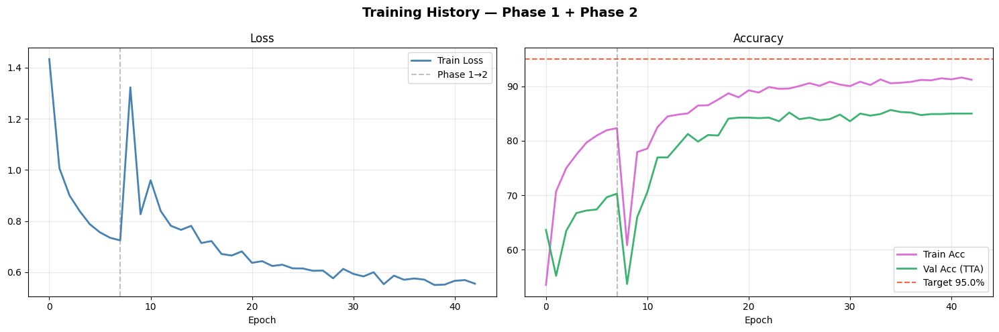

📊 Saved training_history.png


In [9]:
def plot_history(h1, h2):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    fig.suptitle('Training History — Phase 1 + Phase 2', fontsize=14, fontweight='bold')
    p1 = len(h1['train_loss'])
    tr_loss = h1['train_loss'] + h2['train_loss']
    va_tta  = h1['val_acc_tta'] + h2['val_acc_tta']
    tr_acc  = h1['train_acc']  + h2['train_acc']

    axes[0].plot(tr_loss, color='steelblue', lw=2, label='Train Loss')
    axes[0].axvline(p1-1, color='gray', ls='--', alpha=0.5, label='Phase 1→2')
    axes[0].set_title('Loss'); axes[0].set_xlabel('Epoch')
    axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(tr_acc, color='orchid', lw=2, label='Train Acc')
    axes[1].plot(va_tta, color='mediumseagreen', lw=2, label='Val Acc (TTA)')
    axes[1].axhline(CFG['target_acc'], color='tomato', ls='--', lw=1.5, label=f'Target {CFG["target_acc"]}%')
    axes[1].axvline(p1-1, color='gray', ls='--', alpha=0.5)
    axes[1].set_title('Accuracy'); axes[1].set_xlabel('Epoch')
    axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.tight_layout()
    plt.savefig(OUTPUT_DIR/'training_history.png', dpi=150, bbox_inches='tight')
    plt.show(); print('📊 Saved training_history.png')

plot_history(history_p1, history_p2)


## 📊 Cell 8 — Evaluation

✅ Loaded: best_model.pth  |  epoch=27  val=85.19%


Evaluating: 100%|███████████████████████████████| 34/34 [00:19<00:00,  1.71it/s]



🔎 Sanity check: checkpoint reports val_acc=85.19%, evaluation measures raw=85.19% / tta=85.66%

Classification Report (TTA)
                                  precision    recall  f1-score   support

Central Serous Chorioretinopathy     0.6667    1.0000    0.8000        20
            Diabetic Retinopathy     0.9929    0.9272    0.9589       302
                      Disc Edema     0.8065    1.0000    0.8929        25
                        Glaucoma     0.8750    0.6741    0.7615       270
                         Healthy     0.8066    0.8341    0.8201       205
                    Macular Scar     0.8119    0.9213    0.8632        89
                          Myopia     0.6853    0.9800    0.8066       100
                       Pterygium     1.0000    1.0000    1.0000         3
              Retinal Detachment     0.9259    1.0000    0.9615        25
            Retinitis Pigmentosa     0.9333    1.0000    0.9655        28

                        accuracy                         0.

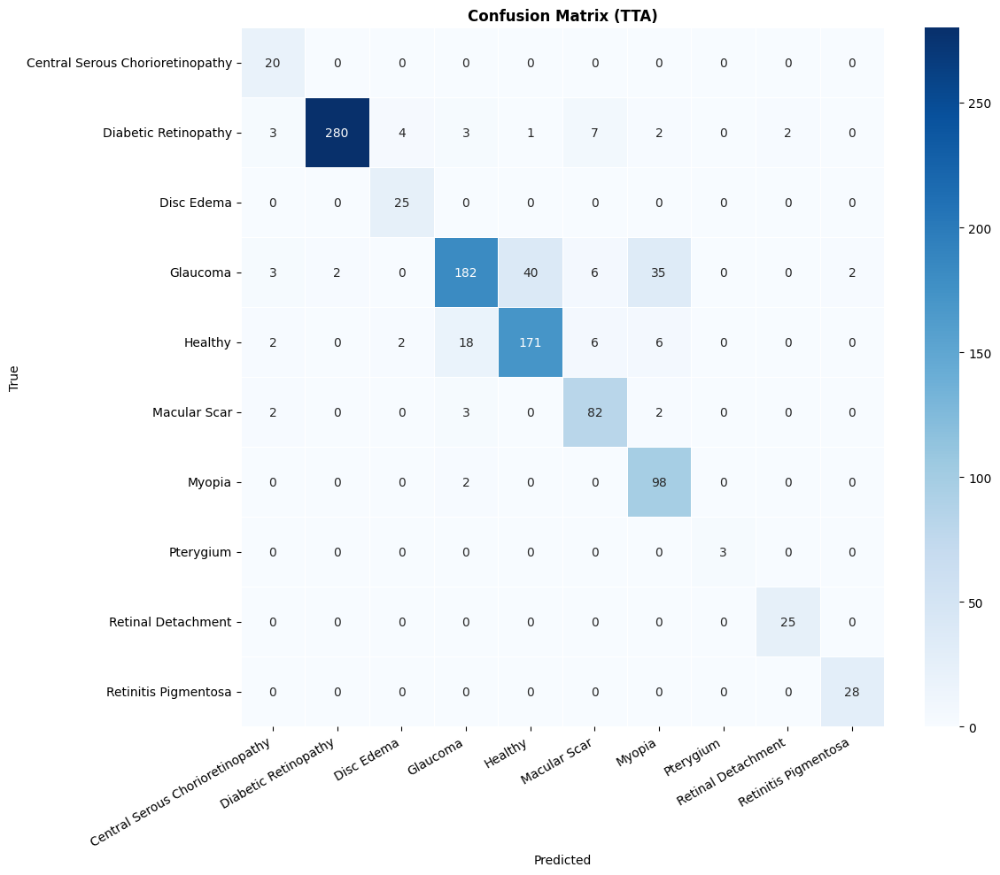

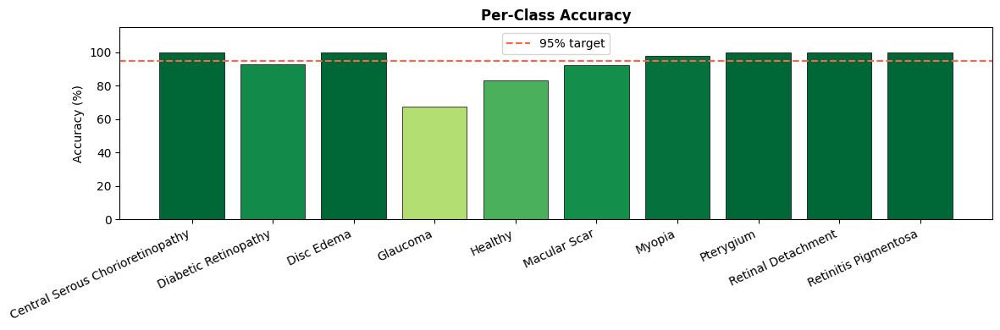

✅ Evaluation complete


In [10]:
# ── GUARD ──────────────────────────────────────────────────────────
if not BEST_MODEL_PATH.exists():
    raise FileNotFoundError(
        f'❌ No checkpoint at {BEST_MODEL_PATH}\n'
        'Complete Cell 6 training first.')

ckpt_info = load_ckpt(model, BEST_MODEL_PATH)
model.eval()


@torch.no_grad()
def evaluate_full(model, loader, use_tta=False):
    model.eval()  # belt & suspenders — guarantees BN/Dropout in eval mode
    all_preds, all_labels, all_probs = [], [], []
    flips = CFG['tta_flips'] if use_tta else ()
    for imgs, lbls in tqdm(loader, desc='Evaluating', ncols=80):
        imgs   = imgs.to(DEVICE, non_blocking=True)
        logits = tta_forward(model, imgs, flips) if use_tta else model(imgs)
        probs  = F.softmax(logits, dim=1)
        all_preds.extend(probs.argmax(1).cpu().numpy())
        all_labels.extend(lbls.numpy())
        all_probs.extend(probs.cpu().numpy())
    return np.array(all_labels), np.array(all_preds), np.array(all_probs)


y_true_raw, y_pred_raw, _ = evaluate_full(model, val_loader, use_tta=False)
y_true, y_pred, y_probs   = evaluate_full(model, val_loader, use_tta=CFG['eval_tta'])

raw_acc  = accuracy_score(y_true_raw, y_pred_raw)*100
tta_acc  = accuracy_score(y_true, y_pred)*100
macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)

# Sanity vs training-time stored accuracy
ckpt_va = float(ckpt_info.get('val_acc', 0)) if isinstance(ckpt_info, dict) else 0
print(f'\n🔎 Sanity check: checkpoint reports val_acc={ckpt_va:.2f}%, '
      f'evaluation measures raw={raw_acc:.2f}% / tta={tta_acc:.2f}%')
if ckpt_va > 50 and raw_acc < 20:
    print('   ❌ Big mismatch — saved model state is corrupt or BN running stats are broken.')
    print('   ➤  Delete models/best_model.pth and rerun Cell 6 (the new training cell '
          'has a verify-on-save guard that prevents this).')

print('\nClassification Report (TTA)')
print('='*65)
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4, zero_division=0))
print(f'Raw Accuracy : {raw_acc:.2f}%  |  TTA Accuracy : {tta_acc:.2f}%  |  Macro F1 : {macro_f1:.4f}')

pred_counts = np.bincount(y_pred, minlength=NUM_CLASSES)
if (pred_counts > 0).sum() <= 2:
    print('\n⚠ WARNING: predictions collapsed — delete models/ and rerun Cell 6.')
else:
    print(f'\n✅ {(pred_counts>0).sum()}/{NUM_CLASSES} classes predicted')

if tta_acc >= TARGET_ACC:
    print(f'🎯 TARGET HIT: {tta_acc:.2f}% ≥ {TARGET_ACC}%')

# Confusion matrix
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(12,10))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=ax, linewidths=0.4)
ax.set_xlabel('Predicted'); ax.set_ylabel('True')
ax.set_title('Confusion Matrix (TTA)', fontweight='bold')
plt.xticks(rotation=30, ha='right'); plt.tight_layout()
plt.savefig(OUTPUT_DIR/'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

# Per-class accuracy
per_cls_acc = np.divide(cm.diagonal(), cm.sum(axis=1),
                        out=np.zeros(NUM_CLASSES), where=cm.sum(axis=1)!=0)
fig, ax = plt.subplots(figsize=(12,4))
ax.bar(CLASS_NAMES, per_cls_acc*100, color=plt.cm.RdYlGn(per_cls_acc),
       edgecolor='black', lw=0.5)
ax.axhline(95, color='tomato', ls='--', lw=1.5, label='95% target')
ax.set_ylim(0,115); ax.set_ylabel('Accuracy (%)'); ax.legend()
ax.set_title('Per-Class Accuracy', fontweight='bold')
plt.xticks(rotation=25, ha='right'); plt.tight_layout()
plt.savefig(OUTPUT_DIR/'per_class_accuracy.png', dpi=150, bbox_inches='tight')
plt.show()
print('✅ Evaluation complete')


## 💾 Cell 9 — Save Central Model

In [11]:
# ══════════════════════════════════════════════════════════════════
#  CELL 9 — SAVE CENTRAL MODEL + CPU TORCHSCRIPT EXPORT
# ══════════════════════════════════════════════════════════════════

ckpt = load_ckpt(model, BEST_MODEL_PATH)
model.eval()

print("🔄 Exporting TorchScript on CPU for portability...")

export_model = copy.deepcopy(model).cpu().eval()
dummy_cpu = torch.randn(1, 3, IMG_SIZE, IMG_SIZE)

with torch.no_grad():
    traced = torch.jit.trace(export_model, dummy_cpu, strict=False)

torch.jit.save(traced, str(TS_MODEL_PATH))

loaded_ts = torch.jit.load(str(TS_MODEL_PATH), map_location="cpu").eval()

with torch.no_grad():
    ref = export_model(dummy_cpu)
    out = loaded_ts(dummy_cpu)
    diff = (ref - out).abs().max().item()

assert diff < 1e-4, f"TorchScript mismatch: {diff}"
print(f"✅ TorchScript verified on CPU (max diff: {diff:.2e})")

metadata = {
    "architecture"  : MODEL_NAME,
    "backbone"      : "EfficientNet-B3 (ImageNet pretrained, used as feature extractor)",
    "custom_modules": [
        "CBAM (Channel + Spatial Attention) at 3 scales",
        "Multi-Scale 1x1 projection to shared 256-d embedding",
        "Cross-Scale Feature Fusion (concatenation)",
        "Custom 3-layer classifier head with progressive dropout decay",
    ],
    "scale_channels": list(model._scale_channels),
    "num_classes"   : NUM_CLASSES,
    "class_names"   : CLASS_NAMES,
    "img_size"      : IMG_SIZE,
    "normalization" : {"mean": [0.485,0.456,0.406], "std": [0.229,0.224,0.225]},
    "cfg"           : {k:(list(v) if isinstance(v,tuple) else v) for k,v in CFG.items()},
    "checkpoint"    : {
        "selected_source": ckpt.get("selected_source", "unknown") if isinstance(ckpt, dict) else "unknown",
        "score": ckpt.get("score", None) if isinstance(ckpt, dict) else None,
        "val_acc": ckpt.get("val_acc", None) if isinstance(ckpt, dict) else None,
        "val_acc_tta": ckpt.get("val_acc_tta", None) if isinstance(ckpt, dict) else None,
    }
}

with open(MODEL_DIR / "model_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

# Keep active model on selected device for XAI/inference cells.
model.to(DEVICE).eval()

del export_model, loaded_ts, dummy_cpu
if USE_CUDA:
    torch.cuda.empty_cache()

print("\n📦 Saved files:")
for p in [BEST_MODEL_PATH, TS_MODEL_PATH, MODEL_DIR / "model_metadata.json"]:
    if p.exists():
        print(f"   {p.name:<35} {p.stat().st_size/1e6:.1f} MB")

print("✅ Central model saved")


✅ Loaded: best_model.pth  |  epoch=27  val=85.19%
🔄 Exporting TorchScript on CPU for portability...
✅ TorchScript verified on CPU (max diff: 0.00e+00)

📦 Saved files:
   best_model.pth                      144.4 MB
   model_torchscript.pt                49.3 MB
   model_metadata.json                 0.0 MB
✅ Central model saved


## 🔍 Cell 10 — XAI: Grad-CAM

Grad-CAM highlights the image regions the model focused on when making its prediction.  
We hook the **last convolutional block** of EfficientNet-B3 (`features[-1]`).


✅ Loaded: best_model.pth  |  epoch=27  val=85.19%


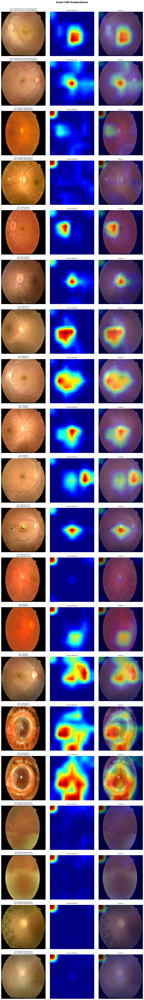

✅ Grad-CAM saved → /kaggle/working/outputs/xai/gradcam_all_classes.png


In [12]:
# ══════════════════════════════════════════════════════════════════
#  GRAD-CAM  (hooks on EfficientNet-B3 final feature block)
# ══════════════════════════════════════════════════════════════════

class GradCAM:
    """
    Gradient-weighted Class Activation Mapping.

    Registers forward + full-backward hooks on `target_layer`,
    computes CAM = ReLU( mean(gradients) * activations ) per channel,
    bilinearly up-samples to input resolution, and overlays on image.
    """
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model        = model
        self.target_layer = target_layer
        self._activations = None
        self._gradients   = None
        self._hooks       = []
        self._register()

    def _register(self):
        def fwd(module, inp, out):
            self._activations = out.detach()

        def bwd(module, grad_in, grad_out):
            self._gradients = grad_out[0].detach()

        self._hooks.append(self.target_layer.register_forward_hook(fwd))
        self._hooks.append(self.target_layer.register_full_backward_hook(bwd))

    def remove(self):
        for h in self._hooks: h.remove()

    def __call__(self, img_tensor: torch.Tensor, class_idx: int = None):
        """
        Args:
            img_tensor : (1,3,H,W) normalised tensor on DEVICE
            class_idx  : target class (None → argmax of prediction)
        Returns:
            cam      : (H,W) normalised heat-map [0,1]
            overlay  : (H,W,3) uint8 BGR→RGB overlay
            pred_idx : predicted class index
        """
        self.model.eval()
        img_tensor = img_tensor.to(DEVICE).requires_grad_(True)

        logits  = self.model(img_tensor)
        pred_idx = int(logits.argmax(dim=1).item()) if class_idx is None else class_idx

        self.model.zero_grad()
        logits[0, pred_idx].backward()

        # Grad-CAM: spatial average of gradients → channel weights
        weights = self._gradients.mean(dim=(2, 3), keepdim=True)   # (1,C,1,1)
        cam     = (weights * self._activations).sum(dim=1, keepdim=True)  # (1,1,h,w)
        cam     = F.relu(cam)
        cam     = F.interpolate(cam, size=img_tensor.shape[2:],
                                mode='bilinear', align_corners=False)
        cam     = cam.squeeze().cpu().numpy()
        if cam.max() > cam.min():
            cam = (cam - cam.min()) / (cam.max() - cam.min())

        # Overlay
        orig = self._denorm(img_tensor.squeeze(0).detach().cpu())
        overlay = self._overlay(cam, orig)
        return cam, overlay, pred_idx

    @staticmethod
    def _denorm(t: torch.Tensor) -> np.ndarray:
        mean = np.array([0.485, 0.456, 0.406])
        std  = np.array([0.229, 0.224, 0.225])
        img  = t.permute(1,2,0).numpy()
        img  = std * img + mean
        return (np.clip(img, 0, 1) * 255).astype(np.uint8)

    @staticmethod
    def _overlay(cam: np.ndarray, orig: np.ndarray, alpha=0.45) -> np.ndarray:
        heatmap = cv2.applyColorMap((cam*255).astype(np.uint8), cv2.COLORMAP_JET)
        heatmap = cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB)
        overlay = cv2.addWeighted(orig, 1-alpha, heatmap, alpha, 0)
        return overlay


def run_gradcam(model, val_dataset, n_per_class=2, save_dir=XAI_DIR):
    """Run Grad-CAM on n_per_class validation samples per class."""
    # Target layer for MSCA-Net: last conv block of the high-level pathway
    # (just before CBAM attention is applied) — captures rich semantic features.
    if hasattr(model, 'stage3'):
        target_layer = model.stage3[-1]      # MSCA-Net (custom)
    elif hasattr(model, 'features'):
        target_layer = model.features[-1]    # fallback: stock torchvision CNN
    else:
        raise RuntimeError('Cannot locate a target layer for Grad-CAM.')
    gcam = GradCAM(model, target_layer)
    save_dir.mkdir(exist_ok=True)

    # Build index: class → list of (img_path, tensor) from val set
    class_samples = defaultdict(list)
    for idx in range(len(val_dataset)):
        real_idx = val_dataset.indices[idx] if hasattr(val_dataset, 'indices') else idx
        path, lbl = org_val_ds.samples[real_idx]
        if len(class_samples[lbl]) < n_per_class:
            class_samples[lbl].append((path, lbl))
        if all(len(v) >= n_per_class for v in class_samples.values()) and len(class_samples) == NUM_CLASSES:
            break

    all_images = [(path, lbl) for lbl in range(NUM_CLASSES) for path, _ in class_samples.get(lbl, [])]
    n_cols = 3   # original | grad-cam | overlay
    n_rows = len(all_images)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols*4, n_rows*4))
    if n_rows == 1: axes = [axes]

    for row, (path, true_lbl) in enumerate(all_images):
        img_pil = Image.open(path).convert('RGB')
        tensor  = VAL_TF(img_pil).unsqueeze(0)
        cam, overlay, pred_idx = gcam(tensor)

        orig_np = GradCAM._denorm(VAL_TF(img_pil))
        heat_np = cv2.applyColorMap((cam*255).astype(np.uint8), cv2.COLORMAP_JET)
        heat_np = cv2.cvtColor(heat_np, cv2.COLOR_BGR2RGB)

        correct = '✅' if pred_idx == true_lbl else '❌'
        title   = (f'True: {CLASS_NAMES[true_lbl]}\nPred: {CLASS_NAMES[pred_idx]} {correct}')

        axes[row][0].imshow(orig_np);    axes[row][0].set_title(title, fontsize=8); axes[row][0].axis('off')
        axes[row][1].imshow(heat_np);    axes[row][1].set_title('Grad-CAM heat', fontsize=8); axes[row][1].axis('off')
        axes[row][2].imshow(overlay);    axes[row][2].set_title('Overlay', fontsize=8); axes[row][2].axis('off')

    plt.suptitle('Grad-CAM Explanations', fontsize=14, fontweight='bold', y=1.001)
    plt.tight_layout()
    out_path = save_dir / 'gradcam_all_classes.png'
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    gcam.remove()
    print(f'✅ Grad-CAM saved → {out_path}')


load_ckpt(model, BEST_MODEL_PATH)
model.eval()
run_gradcam(model, val_subset, n_per_class=CFG['xai_samples_per_class'])


## 🔎 Cell 11 — XAI: LIME

LIME (Local Interpretable Model-agnostic Explanations) segments the image into super-pixels
and perturbs them to find which regions drove the model's prediction.  
Green regions = **supporting** the predicted class · Red regions = **against** it.


✅ Loaded: best_model.pth  |  epoch=27  val=85.19%
  LIME [1/10] Central Serous Chorioretinopathy  pred=Central Serous Chorioretinopathy ✅  conf=94.1%  (running 1000 perturbations...)


  0%|          | 0/1000 [00:00<?, ?it/s]

  LIME [2/10] Diabetic Retinopathy  pred=Diabetic Retinopathy ✅  conf=93.0%  (running 1000 perturbations...)


  0%|          | 0/1000 [00:00<?, ?it/s]

  LIME [3/10] Disc Edema  pred=Disc Edema ✅  conf=94.2%  (running 1000 perturbations...)


...

  0%|          | 0/1000 [00:00<?, ?it/s]

  LIME [9/10] Retinal Detachment  pred=Retinal Detachment ✅  conf=94.7%  (running 1000 perturbations...)


  0%|          | 0/1000 [00:00<?, ?it/s]

  LIME [10/10] Retinitis Pigmentosa  pred=Retinitis Pigmentosa ✅  conf=94.6%  (running 1000 perturbations...)


  0%|          | 0/1000 [00:00<?, ?it/s]

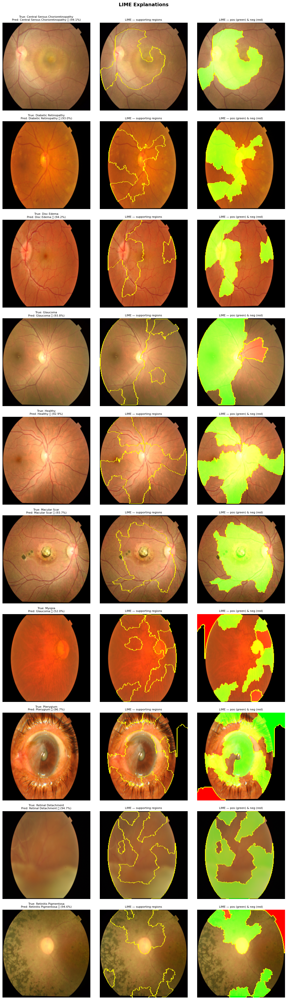

✅ LIME saved → /kaggle/working/outputs/xai/lime_explanations.png


In [13]:
from lime import lime_image
from skimage.segmentation import mark_boundaries

# ── LIME prediction function (batch of numpy HWC → class probabilities) ──
INFER_TF = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225]),
])

def lime_predict_fn(numpy_images: np.ndarray) -> np.ndarray:
    """
    numpy_images : (N, H, W, 3)  float64 [0..1] — LIME's format
    returns      : (N, num_classes) softmax probabilities
    """
    model.eval()
    batch = torch.stack([
        INFER_TF(Image.fromarray((img*255).astype(np.uint8)))
        for img in numpy_images
    ]).to(DEVICE)
    with torch.no_grad():
        probs = F.softmax(model(batch), dim=1).cpu().numpy()
    return probs


def run_lime(model, val_dataset, n_per_class=1, save_dir=XAI_DIR):
    """LIME explanation for n_per_class images per class."""
    explainer = lime_image.LimeImageExplainer(random_state=SEED)
    save_dir.mkdir(exist_ok=True)

    # Gather one sample per class
    class_samples = {}
    for idx in range(len(val_dataset)):
        real_idx = val_dataset.indices[idx] if hasattr(val_dataset, 'indices') else idx
        path, lbl = org_val_ds.samples[real_idx]
        if lbl not in class_samples:
            class_samples[lbl] = path
        if len(class_samples) == NUM_CLASSES: break

    n = len(class_samples)
    fig, axes = plt.subplots(n, 3, figsize=(12, n*4))
    if n == 1: axes = [axes]

    for row, (lbl, path) in enumerate(sorted(class_samples.items())):
        img_pil  = Image.open(path).convert('RGB').resize((IMG_SIZE, IMG_SIZE))
        img_np   = np.array(img_pil).astype(np.float64) / 255.0   # [0,1]

        # Predict
        tensor   = INFER_TF(img_pil).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            probs    = F.softmax(model(tensor), dim=1)[0].cpu().numpy()
        pred_idx = int(probs.argmax())
        correct  = '✅' if pred_idx == lbl else '❌'

        print(f'  LIME [{row+1}/{n}] {CLASS_NAMES[lbl]}  pred={CLASS_NAMES[pred_idx]} {correct}  '
              f'conf={probs[pred_idx]*100:.1f}%  (running {CFG["lime_num_samples"]} perturbations...)')

        explanation = explainer.explain_instance(
            img_np,
            lime_predict_fn,
            top_labels=1,
            hide_color=0,
            num_samples=CFG['lime_num_samples'],
        )

        # Positive (green) segments
        temp_pos, mask_pos = explanation.get_image_and_mask(
            pred_idx,
            positive_only=True,
            num_features=CFG['lime_num_features'],
            hide_rest=False,
        )
        # Both positive + negative (green/red)
        temp_both, mask_both = explanation.get_image_and_mask(
            pred_idx,
            positive_only=False,
            num_features=CFG['lime_num_features'],
            hide_rest=False,
        )

        title = f'True: {CLASS_NAMES[lbl]}\nPred: {CLASS_NAMES[pred_idx]} {correct} ({probs[pred_idx]*100:.1f}%)'
        axes[row][0].imshow(img_np); axes[row][0].set_title(title, fontsize=8); axes[row][0].axis('off')
        axes[row][1].imshow(mark_boundaries(temp_pos, mask_pos))
        axes[row][1].set_title('LIME — supporting regions', fontsize=8); axes[row][1].axis('off')
        axes[row][2].imshow(mark_boundaries(temp_both, mask_both))
        axes[row][2].set_title('LIME — pos (green) & neg (red)', fontsize=8); axes[row][2].axis('off')

    plt.suptitle('LIME Explanations', fontsize=14, fontweight='bold', y=1.001)
    plt.tight_layout()
    out_path = save_dir / 'lime_explanations.png'
    plt.savefig(out_path, dpi=120, bbox_inches='tight')
    plt.show()
    print(f'✅ LIME saved → {out_path}')


load_ckpt(model, BEST_MODEL_PATH)
model.eval()
run_lime(model, val_subset, n_per_class=1)
